# 03 Model checks (small LLM runs)

Checks that need model calls: tens of calls each, not the pipeline. This notebook makes no calls itself. Runner scripts write one JSONL file per run under `experiments/<test>/`, and the sections here read and score those files, so re-running the notebook spends no credits.
Sections are numbered; letters mark parts of one check. Each section carries its own header (question, expected, method, result, mismatch, feeds, and options or open questions).
A mismatch with an expected figure is reported as a mismatch and never adjusted.

**Status: section 1 run.** The checker-versus-reader and filer runs once planned as further sections here were run as the 20-household pilot in notebook 04.

| Section | Test | Parts |
|---|---|---|
| 1 | Model smoke test | a models reached, b valid-output rate, c calls per hour and credits, d three-read agreement, e filer schema variants: valid output |


## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from snapqc.data import ROOT, results_dir

OUT = results_dir("03-model-checks")
SEED = 20261114
rng = np.random.default_rng(SEED)

In [2]:
def load_runs(test: str) -> pd.DataFrame:
    """All JSONL outputs under one experiment folder, one row per model call."""
    files = sorted((ROOT / "experiments" / test).glob("*.jsonl"))
    return pd.concat([pd.read_json(f, lines=True) for f in files], ignore_index=True) if files else pd.DataFrame()

## 1. Model smoke test

- **Question:** Which models can be called, do they return valid output, how fast, and do three reads at temperature 0 agree?
- **Expected:** 95% valid output per model; a measured calls-per-hour figure.
- **Method:** 50 calls per model on every hosted model the key lists (7), with `qwen3.5-397b` and `glm-5.2` as the largest. Inputs are 10 hand-written toy households (`experiments/smoke/fixtures.json`, not QC records, about 200 input tokens each). Per model: 10 households x 3 reads with the forced `report_flags` tool, then 10 filer calls with every form field required and 10 with nullable fields that also accept 'unknown' (validity only here; how often 'unknown' is used is measured in section 3). Temperature 0, `store=False`, reader cap 512 output tokens, filer cap 1,024. Concurrency 5. SDK retries off; our own loop retries 429 and 5xx up to 6 attempts and logs each one. Runner: `experiments/smoke/run_smoke.py` (plus `probe_keys.py` for the two-key bucket check). Valid = status `completed`, exactly one call to the named tool, JSON arguments that pass the tool's JSON schema (enum values included).
- **Result:** All 7 listed models answered all 50 calls. Valid output: gemma-4-26b-a4b-it 100%, gemma-4-31b-it 100%, qwen3.5-397b 98%, deepseek-v4-flash 98%, qwen3.8-27b 96%, glm-5.3-flash 90%, glm-5.2 86% (reader calls alone: 100% for five models, qwen3.5-397b 96.7%, glm-5.2 80%). Every model except the two Gemmas returns a reasoning item before the tool call; 6 of 350 calls hit the output-token cap (5 filer calls at 1,024, 1 reader call at 512). The account has one rate limit across all models and keys: at most 50 answered calls in any 60 s, then HTTP 429 with retry-after 60; 2,283 calls per hour achieved over the run including those waits (ceiling about 3,000), and a second key shares the same 50-call bucket (`1c-key-probe.csv`). Three temperature-0 reads agree on every household with three valid reads, except one household for each Gemma (9 of 10); glm-5.2 has three valid reads on only 7 of 10. The main run cost 0.20 credits (first pass 0.19).
- **Mismatch:** glm-5.3-flash (90%) and glm-5.2 (86%) are below the 95% target. glm-5.2 sends `{}` instead of `{"flags": []}` on 6 of its 9 clean-household reads; glm-5.3-flash sends the string `"unknown"` with its quotes on 3 filer calls. The models page names `glm-53-flash`; the key lists `glm-5.3-flash`. The docs give no rate limit; the key has one. The token-price formula matches `usage.cost` exactly for five models and is 1.3% (gemma-4-26b-a4b-it) and 4.2% (deepseek-v4-flash) above it for the two whose cached input tokens are priced differently from the page.
- **Feeds:** `rq.md` RQ1 (reader and filer shortlist, run time).

In [3]:
import json

runs_smoke = load_runs("smoke")
SMOKE = ROOT / "experiments" / "smoke"
# First pass, kept as evidence of the rate limit: its retry waited 2-8 s instead of the 60 s the server asks for.
files_first = sorted((SMOKE / "run1-short-backoff").glob("*.jsonl"))
runs_first = pd.concat([pd.read_json(f, lines=True) for f in files_first], ignore_index=True)
MODEL_ORDER = ["gemma-4-26b-a4b-it", "gemma-4-31b-it", "qwen3.8-27b", "qwen3.5-397b",
               "glm-5.3-flash", "glm-5.2", "deepseek-v4-flash"]
runs_smoke["model"] = pd.Categorical(runs_smoke.request_model, MODEL_ORDER, ordered=True)
runs_first["model"] = pd.Categorical(runs_first.request_model, MODEL_ORDER, ordered=True)
len(runs_smoke), runs_smoke.groupby("model", observed=True).size().to_dict()

(350,
 {'gemma-4-26b-a4b-it': 50,
  'gemma-4-31b-it': 50,
  'qwen3.8-27b': 50,
  'qwen3.5-397b': 50,
  'glm-5.3-flash': 50,
  'glm-5.2': 50,
  'deepseek-v4-flash': 50})

### 1a. Models reached

`models.list(type="hosted")` on this key, and whether each model answered. Prices are the Adaption models page as of 2026-11-14 (credits per 1M tokens). That page lists `glm-53-flash`; the key lists `glm-5.3-flash`, used here with the same price row.

In [4]:
PRICES = pd.DataFrame([  # model, input, cached input, output (credits per 1M tokens)
    ("gemma-4-31b-it", 0.09, 0.05, 0.34),
    ("gemma-4-26b-a4b-it", 0.077, 0.043, 0.26),
    ("qwen3.5-397b", 0.55, 0.23, 3.50),
    ("qwen3.8-27b", 0.039, 0.0039, 1.25),
    ("glm-5.2", 1.40, 0.26, 4.40),
    ("glm-5.3-flash", 0.15, 0.03, 0.50),
    ("deepseek-v4-flash", 0.045, 0.0015, 0.14),
], columns=["model", "price_in", "price_in_cached", "price_out"]).set_index("model")

listed = json.loads((SMOKE / "models.json").read_text())
models = pd.DataFrame(listed["hosted"])[["id", "display_name", "max_input_tokens", "max_output_tokens"]]
answered = runs_smoke.groupby("request_model").agg(calls=("ok_http", "size"), answered=("ok_http", "sum"))
models = (models.set_index("id").join(answered).join(PRICES)
          .reindex(MODEL_ORDER).rename_axis("model").reset_index())
models.to_csv(OUT / "1a-models.csv", index=False)
print("listed", listed["listed_at"], "SDK", listed["sdk_version"])
models

listed 2026-11-14T04:23:34.872508+00:00 SDK 0.19.0


,model,display_name,max_input_tokens,max_output_tokens,calls,answered,price_in,price_in_cached,price_out
0,gemma-4-26b-a4b-it,Gemma 4 26B A4B Instruct,256000,256000,50,50,0.077,0.0430,0.26
1,gemma-4-31b-it,Gemma 4 31B Instruct,256000,256000,50,50,0.090,0.0500,0.34
2,qwen3.8-27b,Qwen 3.8 27B,262144,262144,50,50,0.039,0.0039,1.25
3,qwen3.5-397b,Qwen 3.5 397B,131072,131072,50,50,0.550,0.2300,3.50
4,glm-5.3-flash,GLM 5.3 Flash,1048576,1048576,50,50,0.150,0.0300,0.50
5,glm-5.2,GLM 5.2,1048575,1048575,50,50,1.400,0.2600,4.40
6,deepseek-v4-flash,DeepSeek V4 Flash,1048576,1048576,50,50,0.045,0.0015,0.14


### 1b. Valid-output rate

All 50 calls per model (30 reader, 20 filer). A call that never got an HTTP answer counts as invalid. The table also shows what came back before the tool call: `reasoning` items (reasoning models), a `message` (text before the call), and calls cut off by the output-token cap.

In [5]:
r = runs_smoke.copy()
r["truncated"] = r.status.eq("incomplete")
r["has_reasoning"] = r.output_types.apply(lambda t: isinstance(t, list) and "reasoning" in t)
r["has_message"] = r.output_types.apply(lambda t: isinstance(t, list) and "message" in t)
valid = r.groupby("model", observed=True).agg(
    calls=("valid", "size"), valid=("valid", "sum"),
    reader_valid=("valid", lambda s: s[r.loc[s.index, "task"].eq("reader")].sum()),
    filer_valid=("valid", lambda s: s[r.loc[s.index, "task"].eq("filer")].sum()),
    no_http_answer=("ok_http", lambda s: (~s).sum()),
    truncated=("truncated", "sum"), with_reasoning=("has_reasoning", "sum"), with_message=("has_message", "sum"),
    median_output_tokens_reader=("output_tokens", lambda s: s[r.loc[s.index, "task"].eq("reader")].median()),
    median_output_tokens_filer=("output_tokens", lambda s: s[r.loc[s.index, "task"].eq("filer")].median()),
    max_reasoning_tokens=("reasoning_tokens", "max"),
)
valid["valid_pct"] = (100 * valid.valid / valid.calls).round(1)
valid["reader_valid_pct"] = (100 * valid.reader_valid / 30).round(1)
valid["meets_95"] = valid.valid_pct >= 95
valid.to_csv(OUT / "1b-valid-output.csv")
valid

,calls,valid,reader_valid,filer_valid,no_http_answer,truncated,with_reasoning,with_message,median_output_tokens_reader,median_output_tokens_filer,max_reasoning_tokens,valid_pct,reader_valid_pct,meets_95
model,,,,,,,,,,,,,,
gemma-4-26b-a4b-it,50,50,30,20,0,0,0,0,18.0,55.5,0,100.0,100.0,True
gemma-4-31b-it,50,50,30,20,0,0,0,1,18.0,55.5,0,100.0,100.0,True
qwen3.8-27b,50,48,30,18,0,2,50,0,200.5,284.0,1024,96.0,100.0,True
qwen3.5-397b,50,49,29,20,0,1,50,0,361.5,443.0,640,98.0,96.7,True
glm-5.3-flash,50,45,30,15,0,2,50,0,170.5,305.5,1024,90.0,100.0,False
glm-5.2,50,43,24,19,0,0,50,0,213.0,280.0,900,86.0,80.0,False
deepseek-v4-flash,50,49,30,19,0,1,50,0,181.0,309.5,959,98.0,100.0,True


In [6]:
reasons = (r[~r.valid].assign(reason=lambda d: d.invalid_reason.str.split(":").str[0])
           .groupby(["model", "task", "variant", "reason"], observed=True).size().rename("calls").reset_index())
reasons.to_csv(OUT / "1b-invalid-reasons.csv", index=False)
reasons

,model,task,variant,reason,calls
0,qwen3.8-27b,filer,nullable_unknown,status_incomplete,2
1,qwen3.5-397b,reader,forced_flags,status_incomplete,1
2,glm-5.3-flash,filer,nullable_unknown,schema_error,3
3,glm-5.3-flash,filer,nullable_unknown,status_incomplete,1
4,glm-5.3-flash,filer,required,status_incomplete,1
5,glm-5.2,filer,required,schema_error,1
6,glm-5.2,reader,forced_flags,schema_error,6
7,deepseek-v4-flash,filer,nullable_unknown,status_incomplete,1


In [7]:
# The invalid calls with their raw arguments (kept in the JSONL, so a parse rule can change without new calls).
r.loc[~r.valid & r.ok_http, ["model", "task", "variant", "household", "read", "invalid_reason",
                             "output_tokens", "reasoning_tokens", "function_call_arguments"]]

,model,task,variant,household,read,invalid_reason,output_tokens,reasoning_tokens,function_call_arguments
49,deepseek-v4-flash,filer,nullable_unknown,H08,1,status_incomplete,1024,959,NaN
150,glm-5.2,reader,forced_flags,H01,1,schema_error: 'flags' is a required property,192,180,{}
155,glm-5.2,reader,forced_flags,H07,1,schema_error: 'flags' is a required property,166,154,{}
159,glm-5.2,reader,forced_flags,H09,1,schema_error: 'flags' is a required property,216,204,{}
165,glm-5.2,reader,forced_flags,H07,2,schema_error: 'flags' is a required property,166,154,{}
170,glm-5.2,reader,forced_flags,H01,3,schema_error: 'flags' is a required property,192,180,{}
174,glm-5.2,reader,forced_flags,H07,3,schema_error: 'flags' is a required property,166,154,{}
182,glm-5.2,filer,required,H03,1,schema_error: 'household_size' is a required p...,229,217,{}
239,glm-5.3-flash,filer,nullable_unknown,H03,1,"schema_error: '""unknown""' is not one of ['unkn...",193,139,"{""earned_income_monthly"": 0, ""household_size"":..."
240,glm-5.3-flash,filer,required,H03,1,status_incomplete,1024,1024,NaN


### 1c. Calls per hour and credits

The key has one inference rate limit for the user, shared by all models: past it the API returns HTTP 429 with "Inference rate limit reached for this user; retry after 60 seconds" and `retry-after: 60`. No rate-limit headers come back on successful calls. The models were run one after another, so the limit is measured on the whole run (all models together), from the times successful calls ended.

In [8]:
def per_minute(d: pd.DataFrame) -> pd.Series:
    ok = d.loc[d.ok_http, "t_end"]
    return np.floor((ok - d.t_start.min()) / 60).astype(int).value_counts().sort_index()

def max_in_window(d: pd.DataFrame, w: float = 60) -> int:
    ok = np.sort(d.loc[d.ok_http, "t_end"].to_numpy())
    return int(max(((ok >= t) & (ok < t + w)).sum() for t in ok))

def first_429(d: pd.DataFrame) -> tuple[int, float]:
    """Successful calls before the first 429, and seconds from the first call to that 429."""
    t429 = min(row.t_start + e["latency_s"] for row in d.itertuples() for e in row.errors if e["status"] == 429)
    return int((d.loc[d.ok_http, "t_end"] < t429).sum()), round(t429 - d.t_start.min(), 1)

rate = pd.DataFrame({
    "run": ["first pass (2-8 s backoff)", "main run (waits retry-after)"],
    "calls": [len(runs_first), len(runs_smoke)],
    "answered": [int(runs_first.ok_http.sum()), int(runs_smoke.ok_http.sum())],
    "http_429": [sum(e["status"] == 429 for l in d.errors for e in l) for d in (runs_first, runs_smoke)],
    "wall_min": [round((d.t_end.max() - d.t_start.min()) / 60, 1) for d in (runs_first, runs_smoke)],
    "max_ok_in_any_60s": [max_in_window(d) for d in (runs_first, runs_smoke)],
    "ok_before_first_429": [first_429(d)[0] if any(len(l) for l in d.errors) else None for d in (runs_first, runs_smoke)],
})
rate["calls_per_hour_achieved"] = (rate.answered / rate.wall_min * 60).round(0)
rate.to_csv(OUT / "1c-rate-limit.csv", index=False)
rate

,run,calls,answered,http_429,wall_min,max_ok_in_any_60s,ok_before_first_429,calls_per_hour_achieved
0,first pass (2-8 s backoff),350,308,257,6.8,60,50,2718.0
1,main run (waits retry-after),350,350,30,9.2,50,50,2283.0


In [9]:
# Two-key probe (experiments/smoke/probe_keys.py): tests whether a second API key gets its own 50/min bucket.
probe = pd.read_json(SMOKE / "rate-probe" / "probe.jsonl", lines=True)
key_probe = (probe.groupby(["phase", "key"], sort=False)
             .agg(calls=("http", "size"), ok_200=("http", lambda s: int((s == 200).sum())),
                  http_429=("http", lambda s: int((s == 429).sum())), credits=("cost", "sum"))
             .reset_index())
key_probe.to_csv(OUT / "1c-key-probe.csv", index=False)
key_probe

,phase,key,calls,ok_200,http_429,credits
0,1_key1_burst,key1,80,50,30,0.000168
1,1_key1_recovery,key1,15,6,9,0.000020
2,2_key2_burst,key2,80,50,30,0.000167
3,3_both_keys_burst,key1,80,50,30,0.000161
4,3_both_keys_burst,key2,80,0,80,0.000000
5,4_key2_then_key1,key2,55,50,5,0.000161
6,4_key2_then_key1,key1,5,0,5,0.000000


{0: 50, 1: 50, 2: 50, 4: 50, 5: 39, 6: 11, 7: 50, 8: 35, 9: 15}

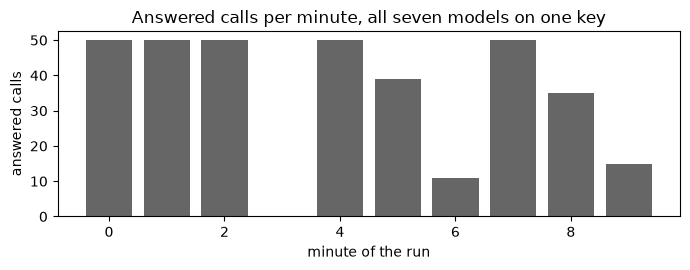

In [10]:
pm = per_minute(runs_smoke)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(pm.index, pm.values, color="0.4")
ax.set_xlabel("minute of the run")
ax.set_ylabel("answered calls")
ax.set_title("Answered calls per minute, all seven models on one key")
fig.tight_layout()
fig.savefig(OUT / "1c-calls-per-minute.svg")
pm.to_frame("answered_calls").rename_axis("minute").to_csv(OUT / "1c-calls-per-minute.csv")
pm.to_dict()

In [11]:
lat = r[r.ok_http].groupby("model", observed=True).agg(
    median_latency_s=("latency_s", "median"),
    p90_latency_s=("latency_s", lambda s: s.quantile(0.9)),
    retries=("retries", "sum"),
)
# Latency here includes waits for 429 retries; the per-attempt time of answered calls is the last attempt.
lat["median_latency_no_retry_s"] = r[r.ok_http & r.retries.eq(0)].groupby("model", observed=True).latency_s.median()
lat["calls_per_hour_one_stream"] = (3600 / lat.median_latency_no_retry_s).round(0)
lat = lat.round(2)
lat.to_csv(OUT / "1c-latency.csv")
lat

,median_latency_s,p90_latency_s,retries,median_latency_no_retry_s,calls_per_hour_one_stream
model,,,,,
gemma-4-26b-a4b-it,0.64,0.76,0,0.64,5616.0
gemma-4-31b-it,0.98,7.75,5,0.78,4621.0
qwen3.8-27b,2.52,14.13,5,2.48,1455.0
qwen3.5-397b,4.09,13.49,5,4.03,893.0
glm-5.3-flash,1.72,12.63,5,1.68,2144.0
glm-5.2,2.45,14.13,5,2.38,1509.0
deepseek-v4-flash,2.32,14.12,5,2.25,1599.0


In [12]:
tok = r[r.ok_http].groupby("model", observed=True).agg(
    input_tokens=("input_tokens", "sum"), cached_tokens=("cached_tokens", "sum"),
    output_tokens=("output_tokens", "sum"), reasoning_tokens=("reasoning_tokens", "sum"),
    credits_reported=("cost", "sum"),
).join(PRICES)
tok["credits_formula"] = ((tok.input_tokens - tok.cached_tokens) * tok.price_in
                          + tok.cached_tokens * tok.price_in_cached
                          + tok.output_tokens * tok.price_out) / 1e6
tok["formula_minus_reported"] = tok.credits_formula - tok.credits_reported
tok["credits_per_reader_call"] = (r[r.ok_http & r.task.eq("reader")].groupby("model", observed=True).cost.mean())
credits = tok.drop(columns=["price_in", "price_in_cached", "price_out"])
credits.loc["total"] = credits.sum(numeric_only=True)
credits.loc["total", "credits_per_reader_call"] = np.nan
credits.to_csv(OUT / "1c-credits.csv")
first_pass_credits = runs_first.cost.sum()
print(f"main run {credits.loc['total', 'credits_reported']:.4f} credits; first pass {first_pass_credits:.4f}")
credits

main run 0.1997 credits; first pass 0.1863


,input_tokens,cached_tokens,output_tokens,reasoning_tokens,credits_reported,credits_formula,formula_minus_reported,credits_per_reader_call
model,,,,,,,,
gemma-4-26b-a4b-it,19274,14592,1689,0,0.001409,0.001427,1.808200e-05,0.000024
gemma-4-31b-it,19274,14720,1785,0,0.001753,0.001753,0.000000e+00,0.000030
qwen3.8-27b,32312,0,15603,12899,0.020764,0.020764,0.000000e+00,0.000308
qwen3.5-397b,30412,0,20680,17656,0.089107,0.089107,9.006684e-15,0.001626
glm-5.3-flash,23694,0,13520,12107,0.010314,0.010314,1.500015e-14,0.000152
glm-5.2,23694,16896,13707,12223,0.074221,0.074221,4.996004e-15,0.001164
deepseek-v4-flash,34422,24320,12397,8324,0.002136,0.002227,9.056060e-05,0.000032
total,183082,70528,79381,63209,0.199703,0.199812,1.086426e-04,NaN


`usage.cost` is returned on every call but is not in the docs; the formula check above is what says it is in credits. The account page balance was not read in this notebook.

### 1d. Three-read agreement

Exact match of the flag set across the three temperature-0 reads of each household. Two denominators: households with three valid reads, and all 10 (a household with any invalid read counts as disagreeing). The toy households have planted errors (`planted` in the fixtures); the last two columns say how many majority answers match them. That is a check of the fixtures and the parse, not an accuracy estimate.

In [13]:
fix = {h["id"]: sorted(h["planted"]) for h in json.loads((SMOKE / "fixtures.json").read_text())["households"]}
rd = r[r.task.eq("reader")].copy()
rd["flagset"] = rd.parsed.apply(lambda p: tuple(p) if isinstance(p, list) else None)

def agree(g: pd.DataFrame) -> pd.Series:
    sets = g.sort_values("read").flagset.tolist()
    all_valid = len(sets) == 3 and all(s is not None for s in sets)
    vals = [s for s in sets if s is not None]
    major = max(set(vals), key=vals.count) if vals and vals.count(max(set(vals), key=vals.count)) >= 2 else None
    return pd.Series({"all_valid": all_valid, "agree": all_valid and len(set(sets)) == 1,
                      "majority_matches_planted": major is not None and list(major) == fix[g.household.iloc[0]]})

per_h = rd.groupby(["model", "household"], observed=True)[["read", "flagset", "household"]].apply(agree).reset_index()
agreement = per_h.groupby("model", observed=True).agg(
    households=("household", "size"), three_valid=("all_valid", "sum"), agree=("agree", "sum"),
    majority_matches_planted=("majority_matches_planted", "sum"))
agreement["agree_pct_of_three_valid"] = (100 * agreement.agree / agreement.three_valid).round(1)
agreement["agree_pct_of_all"] = (100 * agreement.agree / agreement.households).round(1)
agreement.to_csv(OUT / "1d-agreement.csv")
agreement

,households,three_valid,agree,majority_matches_planted,agree_pct_of_three_valid,agree_pct_of_all
model,,,,,,
gemma-4-26b-a4b-it,10,10,9,5,90.0,90.0
gemma-4-31b-it,10,10,9,5,90.0,90.0
qwen3.8-27b,10,10,10,10,100.0,100.0
qwen3.5-397b,10,9,9,10,100.0,90.0
glm-5.3-flash,10,10,10,10,100.0,100.0
glm-5.2,10,7,7,8,100.0,70.0
deepseek-v4-flash,10,10,10,10,100.0,100.0


In [14]:
# Households where the three reads differ, with the flag sets returned (None = invalid read).
dis = rd.pivot_table(index=["model", "household"], columns="read", values="flagset", aggfunc="first", observed=True)
dis[dis.apply(lambda row: len(set(row)) > 1, axis=1)]

read                                                         1  \
model              household                                     
gemma-4-26b-a4b-it H07        (earned_income, unearned_income)   
gemma-4-31b-it     H07                      (unearned_income,)   
qwen3.5-397b       H05                            (utilities,)   
glm-5.2            H01                                     NaN   
                   H09                                     NaN   

read                                           2                   3  
model              household                                          
gemma-4-26b-a4b-it H07        (unearned_income,)  (unearned_income,)  
gemma-4-31b-it     H07                        ()  (unearned_income,)  
qwen3.5-397b       H05              (utilities,)                 NaN  
glm-5.2            H01                        ()                 NaN  
                   H09                        ()                  ()

### 1e. Filer schema variants: valid output

10 filer calls per variant per model. *required*: every money field is a number. *nullable_unknown*: each money field is a number, null or the string 'unknown' (JSON schema `anyOf`), and the instructions say to enter 'unknown' when a document is missing. Four of the ten folders lack one document. The last column counts calls that used null or 'unknown' at all, only to show the variant reaches the model; how often it is used is measured in section 3.

In [15]:
fl = r[r.task.eq("filer")].copy()
fl["used_null_or_unknown"] = fl.parsed.apply(
    lambda p: isinstance(p, dict) and any(v is None or v == "unknown" for v in p.values()))
filer = fl.groupby(["model", "variant"], observed=True).agg(
    calls=("valid", "size"), valid=("valid", "sum"), truncated=("status", lambda s: s.eq("incomplete").sum()),
    schema_errors=("invalid_reason", lambda s: s.fillna("").str.startswith("schema_error").sum()),
    no_http_answer=("ok_http", lambda s: (~s).sum()), used_null_or_unknown=("used_null_or_unknown", "sum"))
filer["valid_pct"] = (100 * filer.valid / filer.calls).round(1)
filer = filer.unstack("variant")
filer.to_csv(OUT / "1e-filer-validity.csv")
filer[["valid_pct", "truncated", "schema_errors", "used_null_or_unknown"]]

valid_pct                 truncated           \
variant            nullable_unknown required nullable_unknown required   
model                                                                    
gemma-4-26b-a4b-it            100.0    100.0                0        0   
gemma-4-31b-it                100.0    100.0                0        0   
qwen3.8-27b                    80.0    100.0                2        0   
qwen3.5-397b                  100.0    100.0                0        0   
glm-5.3-flash                  60.0     90.0                1        1   
glm-5.2                       100.0     90.0                0        0   
deepseek-v4-flash              90.0    100.0                1        0   

                      schema_errors          used_null_or_unknown           
variant            nullable_unknown required     nullable_unknown required  
model                                                                       
gemma-4-26b-a4b-it                0        0                    1        0  
gemma-4-31b-it                    0        0                    1        0  
qwen3.8-27b                       0        0                    7        0  
qwen3.5-397b                      0        0                    6        0  
glm-5.3-flash                     3        0                    4        0  
glm-5.2                           0        1                    6        0  
deepseek-v4-flash                 0        0                    2        0